# **4.8 Numerical stability and model initialization**
So far, every model we have implemented has initialized its parameters based on a predefined distribution. Some might take the initialization scheme for granted, overlooking the details of how these choices are made. Others might even feel that the choice of initialization scheme is not particularly important. On the contrary, the choice of initialization scheme plays a pivotal role in neural network learning and is crucial for maintaining numerical stability. Furthermore, the choice of these initialization schemes can be interestingly combined with the selection of nonlinear activation functions. **Which function we choose and how we initialize its parameters can determine how quickly the optimization algorithm converges. Poor choices may lead to gradient explosion or gradient vanishing during training**.

## **4.8.1 Gradient Vanishing and Gradient Explosion**
Consider a deep neural network with $L$ layers, an input $x$, and an output $o$. Each layer $l$ is defined by a transformation $f_l$, whose parameters are the weights $W^{(l)}$, and whose hidden variable is $h^{(l)} (let \, h^{(0)} = x)$. Our network can be represented as:
##### **(4.8.1)**
$$h^{(l)}=f_{l}(h^{(l-1)})\, therefore \, o=f_{L}\circ ... \circ f_{1}(x)$$
If all hidden variables and inputs are vectors, we can write the gradient of $o$ with respect to any set of parameters $W^{(l)}$ as follows:
##### **(4.8.2)**
$$\partial_{W^{(l)}}o=\underbrace{\partial_{h^{(L-1)}}h^{(L)}}_{M^{(L)}\overset{\mathrm{def}}{=}} ·...· \underbrace{\partial_{h^{(l)}}h^{(l + 1)}}_{M^{(l+1)}\overset{\mathrm{def}}{=}} \underbrace{\partial_{W^{(l)}}h^{(l)}}_{v^{(l)}\overset{\mathrm{def}}{=}}$$
In other words, this gradient is the product of $L−l$ matrices $M^{(L)} · ... · M^{(l+1)}$ and the gradient vector $v^{(l)}$. As a result, we are prone to numerical underflow issues. These problems often arise when too many probabilities are multiplied together. A common technique for handling probabilities is to switch to logarithmic space, shifting the computational burden from the mantissa to the exponent. Unfortunately, the problem described above is even more severe: initially, the matrices $M(l)$ may have a wide range of eigenvalues. They may be very small or very large; their products may be very large or very small.<br><br>
The risks posed by unstable gradients extend beyond their numerical representation; they also threaten the stability of our optimization algorithms. We may encounter several issues. **One is the “gradient explosion” problem, where parameter updates are too large, disrupting the model’s stable convergence; the other is the “gradient vanishing” problem, where parameter updates are too small—resulting in virtually no change with each update—which prevents the model from learning**.

### **Vanishing Gradients**
The sigmoid function $1/(1+exp(−x))$ (mentioned in [Section 4.1](./multi_layer_perceptron.ipynb#411-hidden-layer)) was once very popular because it resembles a threshold function. Since early artificial neural networks were inspired by biological neural networks, the idea that a neuron is either fully activated or completely inactive (just like a biological neuron) was very appealing. However, it is a common cause of the vanishing gradient problem. Let’s take a closer look at why the sigmoid function leads to vanishing gradients.

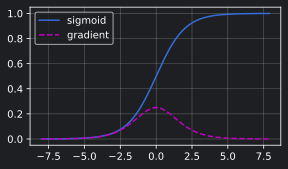

In [1]:
%matplotlib inline
import torch
from d2l import torch as d2l

x = torch.arange(-8.0, 8.0, 0.1, requires_grad=True)
y = torch.sigmoid(x)
y.backward(torch.ones_like(x))

d2l.plot(x.detach().numpy(), [y.detach().numpy(), x.grad.numpy()],
         legend=["sigmoid", "gradient"], figsize=(4.5, 2.5))

As shown in the figure above, **when the input to the sigmoid function is very large or very small, its gradient vanishes. Furthermore, when backpropagation passes through many layers, the gradient of the entire product may vanish unless we happen to be at just the right points—where the input to the sigmoid function is close to zero. When our network has many layers, the gradient may be cut off at a certain layer unless we are very careful.** In fact, this problem once plagued the training of deep networks. As a result, the more stable ReLU family of functions has become the default choice among practitioners (even though it may not seem entirely reasonable from a neuroscientific perspective).

### **Gradient Explosion**
Conversely, gradient explosion can be just as problematic. To illustrate this point, we generate 100 Gaussian random matrices and multiply them by an initial matrix. For the scale we chose (variance σ² = 1), the matrix product explodes. **When this phenomenon is caused by the initialization of a deep network, we have no chance of getting the gradient descent optimizer to converge**.

In [2]:
M = torch.normal(0, 1, size=(4, 4))
print('A matrix \n', M)
for i in range(100):
    M = torch.mm(M, torch.normal(0, 1, size=(4, 4)))

print('After multiplying by 100 matrices\n', M)

A matrix 
 tensor([[-0.0185,  0.6507, -1.9081,  0.1415],
        [-0.6141,  0.5416, -0.0450,  0.6845],
        [ 0.5428, -0.8332, -0.3895, -0.3790],
        [ 0.4754, -0.7334, -0.7564,  0.1503]])
After multiplying by 100 matrices
 tensor([[ 1.6713e+24,  2.1831e+25, -9.1737e+24, -2.6277e+25],
        [-9.3855e+23, -1.2260e+25,  5.1518e+24,  1.4757e+25],
        [ 1.1341e+24,  1.4814e+25, -6.2250e+24, -1.7831e+25],
        [ 8.7021e+23,  1.1367e+25, -4.7766e+24, -1.3682e+25]])


### **Breaking Symmetry**
Another issue in neural network design is the symmetry inherent in their parameterization. Suppose we have a simple multilayer perceptron with one hidden layer and two hidden units. In this case, we can rearrange the weights $W^{(1)}$ of the first layer and, similarly, rearrange the weights of the output layer to obtain the same function. There is no particular difference between the first and second hidden units. In other words, there is permutation symmetry among the hidden units in each layer.<br><br>
Suppose we convert the multi-layer perceptron with the two hidden units described above into one with only a single output unit. Imagine what would happen if we initialized all parameters of the hidden layer as $W^{(1)} = c$, where c is a constant. In this case, during forward propagation, the two hidden units receive the same input and parameters, producing the same activation, which is then sent to the output unit. During backpropagation, the output unit is differentiated with respect to the parameter $W^{(1)}$, yielding a gradient whose elements all take the same value. Consequently, after a gradient-based iteration (such as mini-batch stochastic gradient descent), all elements of $W^{(1)}$ still take the same value. Such iterations will never break this symmetry, and we may never be able to realize the network’s expressive power. The hidden layer behaves as if it had only a single unit. **Note that while mini-batch stochastic gradient descent does not break this symmetry, backpropagation regularization does**.

## **4.8.2 Parameter Initialization**
One way to resolve (or at least mitigate) the above issues is to initialize the parameters; attention during optimization and appropriate regularization can also further improve stability.

### **Default Initialization**
In previous sections, such as [Section 3.3](../../chapter_linear_neural_network/content/concise_implementation_of_linear_regression.ipynb#33-a-concise-implementation-of-linear-regression), we used a normal distribution to initialize the weights. If we do not specify an initialization method, the framework will use the default random initialization method, which is generally effective for problems of moderate difficulty.

### **Xavier Initialization**
Let’s examine the scale distribution of the outputs oi of certain fully connected layers that do not exhibit nonlinearity (e.g., hidden variables). For the inputs $x_j$ and their corresponding weights $w_{ij}$ of this layer $n_{in}$, the output is given by the following equation:
##### **(4.8.3)**
$$o_i = \sum\limits_{j=1}^{n_{in}}w_{ij}x_{j}$$
The weights $w_{ij}$ are all independently drawn from the same distribution. Furthermore, let’s assume that this distribution has a mean of zero and a variance of $\sigma^{2}$. Note that this does not imply that the distribution must be Gaussian; it simply means that the mean and variance must exist. Now, let’s assume that the inputs to layer $x_j$ also have a mean of zero and a variance of $\gamma^2$, and
they are independent of $w_{ij}$ and independent of one another. In this case, we can calculate the mean and variance of $o_i$ as follows:
##### **(4.8.4)**
$$
\begin{align*}
E[o_{i}] &= \sum\limits_{j=1}^{n_{in}}E[w_{ij}x_{j}] \\
&= \sum\limits_{j=1}^{n_{in}}E[w_{ij}E[x_{j}] \\
&= 0
\end{align*}
$$
$$
\begin{align*}
Var[o_{i}] &= E[o_{i}^{2}]-(E[o_{i}])^{2} \\
&= \sum\limits_{j=1}^{n_{in}}E[w_{ij}^{2}x_{j}^{2}]-0 \\
&= \sum\limits_{j=1}^{n_{in}}E[w_{ij}^{2}]E[x_{j}^{2}] \\
&= n_{in} \sigma^{2} \gamma^{2}
\end{align*}
$$
One way to keep the variance constant is to set $n_{in} \sigma^{2}=1$. Now, considering the backpropagation process, we face a similar problem, although the gradients are propagated from layers closer to the output. Using the same reasoning as in forward propagation, we can see that unless $n_{out} \sigma^{2}=1$—where $n_{out}$ is the number of outputs in that layer—the variance of the gradients may increase. This presents us with a dilemma: it is impossible to satisfy both conditions simultaneously. Instead, we need only satisfy:
##### **(4.8.5)**
$$\frac{1}{2}(n_{in}+n_{out})\sigma^{2}=1\;Or\;equivalent\;to\;\sigma = \sqrt{\frac{2}{n_{in}+n_{out}}}$$
This is the basis for the current standard and practical Xavier initialization. **Typically, Xavier initializes weights by sampling from a Gaussian distribution with a mean of zero and a variance of $sigma^{2} = \frac{2}{n_{in}+n_{out}}$**. We can also modify this to use the variance when sampling weights from a uniform distribution. Note that the variance of the uniform distribution $U(−a, a)$ is $\frac{a^2}{3}$. Substituting $\frac{a^2}{3}$ into the condition for $\sigma^2$ yields the initialization range:
##### **(4.8.6)**
$$U \left( -\sqrt{\frac{6}{n_{in}+n_{out}}}, \sqrt{\frac{6}{n_{in}+n_{out}}} \right)$$
Although the assumption of “no nonlinearities” in the above mathematical reasoning is easily violated in neural networks, the Xavier initialization method has proven effective in practice.

## **Summary**
* Gradient vanishing and gradient explosion are common problems in deep neural networks. Great care must be taken when initializing parameters to ensure that gradients and parameters are well-controlled.
* A heuristic initialization method is needed to ensure that the initial gradients are neither too large nor too small.
* The ReLU activation function mitigates the vanishing gradient problem, thereby accelerating convergence.
* Random initialization is key to breaking symmetry before optimization begins.
* Xavier's initialization shows that, for each layer, the variance of the output is independent of the number of inputs, and the variance of any gradient is independent of the number of outputs.